# 02 · Funnel analysis

**Business question:** where do we lose buyers between landing and purchase, which
channels and devices convert, and which fix is worth the most?

**Definitions**
- Unit of analysis: a **session** (non-bot). Stages use "reached this stage *or any later
  stage*", so Buy-Now purchases that skip the cart are counted correctly (DQ-12).
- Stages: Session → Product view → Add to cart → Checkout → Purchase.
- Window: the last 12 complete months (Oct 2025 – Sep 2026), unless stated.
- Funnel conversion is measured from tracked events. 4.4% of orders are untracked (DQ-11),
  so absolute conversion is slightly understated. Comparisons between segments are unaffected
  as long as tracking loss is similar across them; desktop loses more, which makes desktop
  look slightly *worse* than it is.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy import stats

from db import query as q
from run_analysis import run_sql_file
from pathlib import Path
import viz

viz.setup()
A = Path("sql/analysis")


def wilson(k, n, z=1.96):
    """95% Wilson confidence interval for a proportion (better than normal approx near 0)."""
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return c - h, c + h

## 1. The overall funnel

In [2]:
f = run_sql_file(A / "04_funnel_stages.sql")
overall = f[f.device_type == "all devices"].reset_index(drop=True)
overall

,device_type,stage,sessions,step_conversion,sessions_lost_at_step,conversion_from_start
0,all devices,1. Session,493395,NaN,NaN,1.0000
1,all devices,2. Product view,281669,0.5709,211726.0,0.5709
2,all devices,3. Add to cart,49471,0.1756,232198.0,0.1003
3,all devices,4. Checkout,27546,0.5568,21925.0,0.0558
4,all devices,5. Purchase,15461,0.5613,12085.0,0.0313


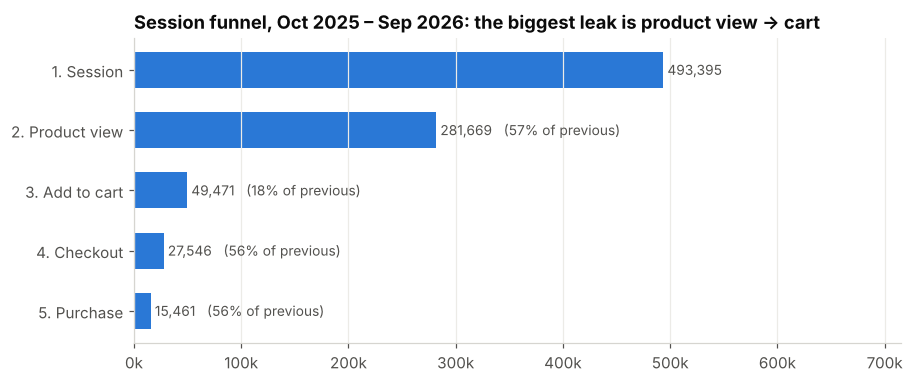

Text(0.0, 1.0, 'Session funnel, Oct 2025 – Sep 2026: the biggest leak is product view → cart')

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(overall.stage[::-1], overall.sessions[::-1], color=viz.BLUE, height=0.6)
for i, r in overall[::-1].reset_index(drop=True).iterrows():
    lab = f"{r.sessions:,.0f}" + ("" if pd.isna(r.step_conversion) else f"   ({r.step_conversion:.0%} of previous)")
    ax.text(r.sessions + 4000, i, lab, va="center", color=viz.INK_2, fontsize=9)
ax.set_xlim(0, overall.sessions.max() * 1.45)
ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1000:.0f}k"))
ax.set_title("Session funnel, Oct 2025 – Sep 2026: the biggest leak is product view → cart")

**Reading the funnel**
- **3.1%** of sessions end in a purchase.
- The largest *volume* loss is **product view → add to cart**: only about 18% of product viewers add
  anything, and about 230k sessions leave at this step.
- The *late* stages lose far fewer sessions, but each of them is worth much more, because
  **a session that reaches checkout is ~10× more likely to convert** than one that only views a product.

So "largest drop-off" and "highest-value opportunity" are different questions. Section 5 sizes them.

## 2. Device: mobile is 81% of sessions but converts at ~58% of the desktop rate (2.8% vs 4.8%)

In [4]:
dev = f[f.device_type != "all devices"].pivot(index="stage", columns="device_type", values="step_conversion")
dev = dev[["mobile", "desktop", "tablet"]].dropna()
dev["mobile_vs_desktop_pp"] = (dev.mobile - dev.desktop) * 100
dev.round(3)

device_type,mobile,desktop,tablet,mobile_vs_desktop_pp
stage,,,,
2. Product view,0.563,0.607,0.589,-4.35
3. Add to cart,0.170,0.197,0.194,-2.62
4. Checkout,0.550,0.585,0.561,-3.55
5. Purchase,0.529,0.688,0.574,-15.86


In [5]:
stg = q("""
select device_type,
       sum(product_view_sessions) pv, sum(cart_sessions) cart,
       sum(checkout_sessions) co, sum(purchase_sessions) buy, sum(sessions) s
from mart.mart_funnel_daily
where session_date between '2025-10-01' and '2026-09-30' and device_type in ('mobile','desktop')
group by 1
""").set_index("device_type")
rows = []
for d in ["mobile", "desktop"]:
    r = stg.loc[d]
    for name, k, n in [("Product view → Cart", r.cart, r.pv), ("Cart → Checkout", r.co, r.cart),
                       ("Checkout → Purchase", r.buy, r.co), ("Session → Purchase", r.buy, r.s)]:
        lo, hi = wilson(k, n)
        rows.append({"device": d, "step": name, "rate": k / n, "ci_low": lo, "ci_high": hi, "n": int(n)})
ci = pd.DataFrame(rows)
ci.round(4)

,device,step,rate,ci_low,ci_high,n
0,mobile,Product view → Cart,0.1704,0.1689,0.1720,224444
1,mobile,Cart → Checkout,0.5499,0.5449,0.5549,38254
2,mobile,Checkout → Purchase,0.5291,0.5224,0.5359,21036
3,mobile,Session → Purchase,0.0279,0.0274,0.0284,398490
4,desktop,Product view → Cart,0.1966,0.1930,0.2003,45315
5,desktop,Cart → Checkout,0.5854,0.5751,0.5956,8910
6,desktop,Checkout → Purchase,0.6877,0.6750,0.7001,5216
7,desktop,Session → Purchase,0.0480,0.0465,0.0496,74692


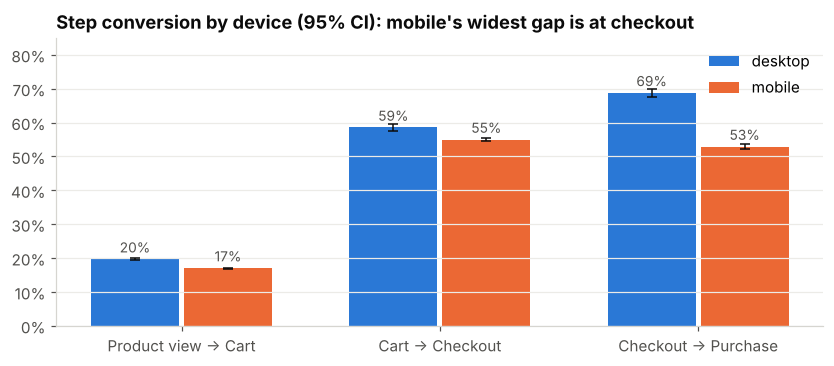

Text(0.0, 1.0, "Step conversion by device (95% CI): mobile's widest gap is at checkout")

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4))
steps = ["Product view → Cart", "Cart → Checkout", "Checkout → Purchase"]
x = np.arange(len(steps))
for j, d in enumerate(["desktop", "mobile"]):
    sub = ci.set_index(["device", "step"]).loc[d].loc[steps]
    ax.bar(x + (j - 0.5) * 0.36, sub.rate, width=0.34, color=viz.DEVICE_COLORS[d], label=d)
    ax.errorbar(x + (j - 0.5) * 0.36, sub.rate, yerr=[sub.rate - sub.ci_low, sub.ci_high - sub.rate],
                fmt="none", ecolor=viz.INK, capsize=3, lw=1)
    for xi, v in zip(x, sub.rate):
        ax.text(xi + (j - 0.5) * 0.36, v + 0.02, f"{v:.0%}", ha="center", fontsize=9, color=viz.INK_2)
ax.set_xticks(x, steps); ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.set_ylim(0, 0.85)
ax.legend(); ax.grid(axis="x", visible=False)
ax.set_title("Step conversion by device (95% CI): mobile's widest gap is at checkout")

The confidence intervals are tiny relative to the gaps (large samples), so these differences are not noise.
The **largest device gap is at the final step**: about 16 points fewer mobile checkouts complete. That points
to payment/checkout friction on mobile (address entry, OTP, payment app hand-off) rather than to weaker
product interest.

## 3. Channel × device conversion

In [7]:
cd = run_sql_file(A / "02_conversion_by_channel_device.sql")
cd

,channel,sessions,mobile_share,conversion_all,conversion_mobile,conversion_desktop,conversion_tablet,conversion_new_visitors
0,ALL CHANNELS,493395,0.808,0.0313,0.0279,0.0480,0.0368,0.0158
1,Paid Social,179124,0.898,0.0132,0.0117,0.0308,0.0153,0.0078
2,Organic Search,96641,0.748,0.0309,0.0293,0.0366,0.0321,0.0190
3,Direct,75145,0.755,0.0560,0.0519,0.0704,0.0623,0.0283
4,Paid Search,71608,0.720,0.0374,0.0361,0.0418,0.0351,0.0263
5,Email,23996,0.791,0.0768,0.0693,0.1068,0.0993,0.0371
6,Affiliate,23874,0.807,0.0376,0.0339,0.0582,0.0330,0.0234
7,Organic Social,16735,0.875,0.0220,0.0184,0.0475,0.0464,0.0097
8,Referral,6272,0.651,0.0188,0.0201,0.0160,0.0190,0.0187


Chi-square test of independence (channel x purchased): chi2=5,293, dof=7, p=0.0e+00


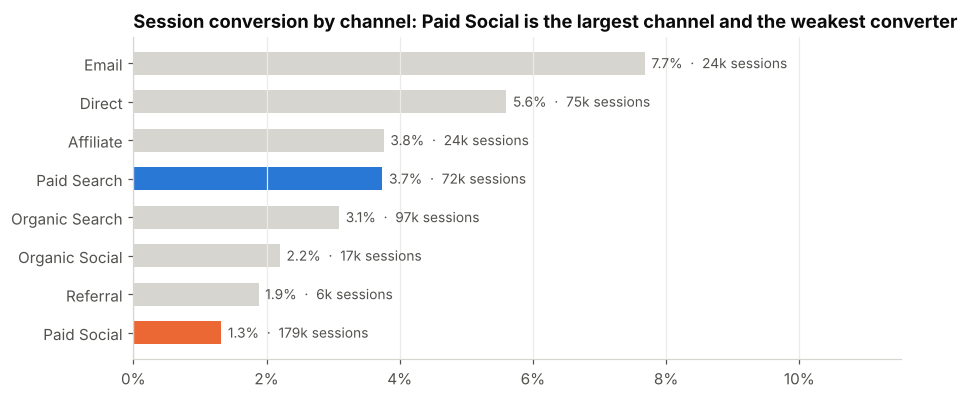

Text(0.0, 1.0, 'Session conversion by channel: Paid Social is the largest channel and the weakest converter')

In [8]:
chan = cd[cd.channel != "ALL CHANNELS"].copy()
ct = q("""
select channel, sum(purchased::int) as buyers, count(*) - sum(purchased::int) as non_buyers
from core.fct_sessions where session_date between '2025-10-01' and '2026-09-30' group by 1
""")
chi2, p, dof, _ = stats.chi2_contingency(ct[["buyers", "non_buyers"]].to_numpy())
print(f"Chi-square test of independence (channel x purchased): chi2={chi2:,.0f}, dof={dof}, p={p:.1e}")

fig, ax = plt.subplots(figsize=(9, 3.8))
chan = chan.sort_values("conversion_all")
ax.barh(chan.channel, chan.conversion_all, color=[viz.highlight(c) for c in chan.channel], height=0.6)
for i, (v, s) in enumerate(zip(chan.conversion_all, chan.sessions)):
    ax.text(v + 0.001, i, f"{v:.1%}  ·  {s / 1000:.0f}k sessions", va="center", fontsize=9, color=viz.INK_2)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_xlim(0, chan.conversion_all.max() * 1.5)
ax.grid(axis="y", visible=False)
ax.set_title("Session conversion by channel: Paid Social is the largest channel and the weakest converter")

- **Paid Social is the largest traffic source (36% of sessions) but converts at 1.3%**, less than half the
  site average. Its traffic is 90% mobile, but device mix doesn't explain the gap: Paid Social converts
  worse than other channels *on every device*. Even on desktop it trails Paid Search.
- **Email and Direct convert best.** Both are mostly existing customers and people returning with intent,
  so they are better read as *demand-capture* channels than as acquisition channels.
- The chi-square test rejects "conversion is the same across channels" (p ≈ 0). With samples this large,
  significance is almost guaranteed; the **size** of the gaps is what matters.

⚠️ Session conversion is a last-click view. It says nothing about whether a channel's *customers*
come back. That is the cohort and LTV question (notebooks 03–04).

## 4. Did the mobile checkout redesign (Aug 2025) work? Difference-in-differences

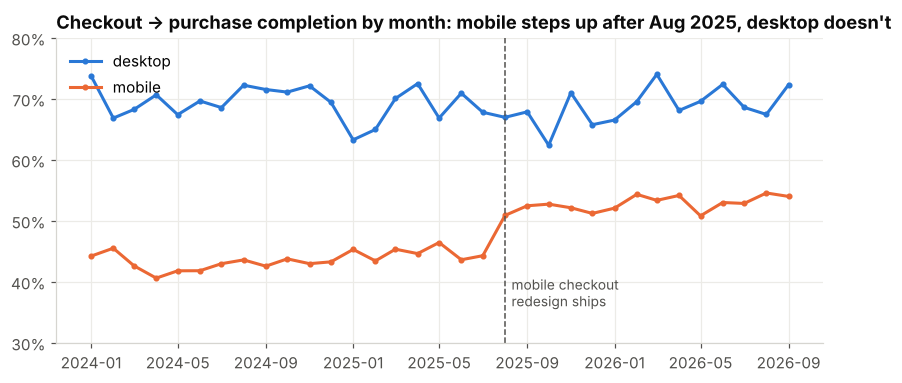

Text(0.0, 1.0, "Checkout → purchase completion by month: mobile steps up after Aug 2025, desktop doesn't")

In [9]:
trend = q("""
select date_trunc('month', session_date) as month, device_type,
       sum(purchase_sessions)::double / sum(checkout_sessions) as checkout_completion
from mart.mart_funnel_daily
where device_type in ('mobile','desktop') and session_date <= '2026-09-30'
group by all order by 1
""")
fig, ax = plt.subplots(figsize=(9, 3.6))
for d in ["desktop", "mobile"]:
    t = trend[trend.device_type == d]
    ax.plot(t.month, t.checkout_completion, color=viz.DEVICE_COLORS[d], label=d, marker="o", ms=3)
ax.axvline(pd.Timestamp("2025-08-01"), color=viz.INK_2, ls="--", lw=1)
ax.text(pd.Timestamp("2025-08-10"), 0.36, "mobile checkout\nredesign ships", fontsize=9, color=viz.INK_2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0.3, 0.8); ax.legend(loc="upper left")
ax.set_title("Checkout → purchase completion by month: mobile steps up after Aug 2025, desktop doesn't")

In [10]:
did = run_sql_file(A / "05_checkout_redesign_diff_in_diff.sql")
did.T.rename(columns={0: "value"})

,value
mobile_pre,0.4464
mobile_post,0.5197
desktop_pre,0.6892
desktop_post,0.6660
mobile_change,0.0732
desktop_change,-0.0231
did_estimate,0.0964
did_ci_low,0.0659
did_ci_high,0.1269


In [11]:
pre = trend[(trend.month >= "2024-02-01") & (trend.month < "2025-08-01")].pivot(index="month", columns="device_type", values="checkout_completion")
gap = (pre.mobile - pre.desktop)
slope = stats.linregress(np.arange(len(gap)), gap.to_numpy())
print(f"Pre-period trend in the mobile-desktop gap: {slope.slope * 100:+.2f} pp/month (p={slope.pvalue:.2f})")

Pre-period trend in the mobile-desktop gap: +0.16 pp/month (p=0.31)


**Result:** mobile checkout completion rose **+7.3 pp** while desktop (untouched) moved −2.3 pp over the
same months. The difference-in-differences estimate is **+9.6 pp (95% CI 6.6 – 12.7)**.

- Desktop is the control because it got the same seasons, sales and marketing but **not** the redesign.
- **Parallel-trends check:** before the launch the mobile–desktop gap had no significant trend (p shown
  above), which supports the comparison.
- **Caveats:** this is observational, not a randomised A/B test. Anything else that changed mobile-only
  in Aug 2025 (a payment-app update, say) would be credited to the redesign. The CI also uses a simple
  binomial SE and ignores day-to-day clustering, so it is probably too narrow.

*(Method-validation note: the generator planted a +8 pp effect, which falls inside the CI. The method
 recovers the truth, and slightly over-estimates it because desktop happened to dip.)*

## 5. Where is the money? Sizing the opportunities (scenarios, not forecasts)

For each step: **revenue at stake** = sessions lost at the step × the probability that a session which
*passed* the step went on to buy × net revenue per order. This is an upper bound, because people who drop
out are less motivated than people who continue. The next table therefore sizes **realistic, explicitly
assumed improvements** instead.

In [12]:
rev = q("""
select sum(net_revenue) / count(*) filter (where is_valid_order) as net_rev_per_valid_order,
       sum(gross_margin) / count(*) filter (where is_valid_order) as margin_per_valid_order,
       avg(is_valid_order::int) as valid_share
from core.fct_orders where order_date between '2025-10-01' and '2026-09-30'
""").iloc[0]
print(rev.round(3).to_string())

m = stg.loc["mobile"]
d_ = stg.loc["desktop"]
o = overall.set_index("stage")
p_after = {  # P(purchase | reached stage), all devices
    "2. Product view": o.loc["5. Purchase", "sessions"] / o.loc["2. Product view", "sessions"],
    "3. Add to cart": o.loc["5. Purchase", "sessions"] / o.loc["3. Add to cart", "sessions"],
    "4. Checkout": o.loc["5. Purchase", "sessions"] / o.loc["4. Checkout", "sessions"],
    "5. Purchase": 1.0,
}
at_stake = pd.DataFrame({
    "step": ["Session → Product view", "Product view → Cart", "Cart → Checkout", "Checkout → Purchase"],
    "sessions_lost": o.sessions_lost_at_step.iloc[1:].to_numpy(),
    "p_purchase_if_passed": list(p_after.values()),
})
at_stake["upper_bound_net_revenue"] = (at_stake.sessions_lost * at_stake.p_purchase_if_passed
                                       * rev.valid_share * rev.net_rev_per_valid_order)
at_stake.round(3)

net_rev_per_valid_order    1831.765
margin_per_valid_order      984.976
valid_share                   0.871


,step,sessions_lost,p_purchase_if_passed,upper_bound_net_revenue
0,Session → Product view,211726.0,0.055,1.855240e+07
1,Product view → Cart,232198.0,0.313,1.158438e+08
2,Cart → Checkout,21925.0,0.561,1.964473e+07
3,Checkout → Purchase,12085.0,1.000,1.929186e+07


In [13]:
scen = []
# A. Mobile checkout: close a further 25% of the remaining gap to desktop
gap_co = d_.buy / d_.co - m.buy / m.co
add_orders_A = m.co * 0.25 * gap_co
scen.append(("A. Mobile checkout completion closes 25% of remaining gap to desktop",
             f"+{0.25 * gap_co * 100:.1f} pp on {m.buy / m.co:.0%}", add_orders_A))
# B. Mobile product view -> cart +1pp absolute
p_buy_given_cart_m = m.buy / m.cart
add_orders_B = m.pv * 0.01 * p_buy_given_cart_m
scen.append(("B. Mobile product view → cart improves by 1 pp", f"{m.cart / m.pv:.1%} → {m.cart / m.pv + .01:.1%}", add_orders_B))
# C. Paid Social traffic converts 10% better (relative) — e.g. better landing pages
ps = chan.set_index("channel").loc["Paid Social"]
add_orders_C = ps.sessions * ps.conversion_all * 0.10
scen.append(("C. Paid Social session conversion +10% relative (landing-page fit)", f"{ps.conversion_all:.2%} → {ps.conversion_all * 1.1:.2%}", add_orders_C))
S = pd.DataFrame(scen, columns=["scenario", "assumed change", "extra_purchase_sessions_per_year"])
S["extra_valid_orders"] = S.extra_purchase_sessions_per_year * rev.valid_share
S["extra_net_revenue_inr"] = S.extra_valid_orders * rev.net_rev_per_valid_order
S["extra_gross_margin_inr"] = S.extra_valid_orders * rev.margin_per_valid_order
S["pct_of_annual_net_revenue"] = S.extra_net_revenue_inr / q(
    "select sum(net_revenue) from core.fct_orders where order_date between '2025-10-01' and '2026-09-30'").iloc[0, 0]
S.round(3)

,scenario,assumed change,extra_purchase_sessions_per_year,extra_valid_orders,extra_net_revenue_inr,extra_gross_margin_inr,pct_of_annual_net_revenue
0,A. Mobile checkout completion closes 25% of remaining gap to desktop,+4.0 pp on 53%,833.821,726.659,1331067.765,715741.046,0.052
1,B. Mobile product view → cart improves by 1 pp,17.0% → 18.0%,653.078,569.145,1042540.175,560594.145,0.040
2,C. Paid Social session conversion +10% relative (landing-page fit),1.32% → 1.45%,236.444,206.056,377446.307,202960.226,0.015


**Assumptions (explicit):** volumes are the last 12 months of tracked sessions (real volume is about 4%
higher because of tracking loss); incremental purchasers behave like average purchasers (same AOV, same
cancel/RTO rate). This is simple scenario arithmetic, not a forecast. Changes in one stage also shift the
mix of later stages.

**Takeaways**
- Closing a quarter of the *remaining* mobile checkout gap (+4 pp) is worth about **₹13L net revenue / ₹7L
  margin a year (~5% of revenue)**. A **1 pp lift in mobile product-view → cart** (+6% relative) is worth about
  **₹10L**. The top of the funnel has more *volume*; the bottom has more *value per session*. Both are worth testing.
- Making Paid Social traffic convert 10% better is worth only about ₹4L, because it touches one channel's
  sessions, while site-wide mobile fixes touch 81% of traffic.
- Prioritisation (impact × effort × confidence) is in `docs/insights_and_recommendations.md`.

## 6. Segments: visitor type and sale periods

In [14]:
seg = q("""
select visitor_type,
       count(*) as sessions,
       avg(purchased::int) as conversion,
       avg(reached_cart::int) as cart_rate,
       sum(purchased::int)::double / nullif(sum(reached_cart::int), 0) as cart_to_purchase
from core.fct_sessions where session_date between '2025-10-01' and '2026-09-30'
group by 1 order by 2 desc
""")
seg.round(4)

,visitor_type,sessions,conversion,cart_rate,cart_to_purchase
0,New visitor,342985,0.0158,0.0625,0.2533
1,Returning prospect,131129,0.0371,0.1256,0.2951
2,Existing customer,19281,0.2679,0.5988,0.4474


In [15]:
sale = q("""
select is_sale_day, count(*) / count(distinct session_date) as sessions_per_day,
       avg(purchased::int) as conversion, avg(reached_cart::int) as cart_rate
from core.fct_sessions where session_date between '2024-01-01' and '2026-09-30'
group by 1
""")
sale.round(4)

,is_sale_day,sessions_per_day,conversion,cart_rate
0,False,1081.8657,0.0282,0.0966
1,True,1604.7767,0.0273,0.1016


- **New visitors convert at 1.6%**, returning prospects at 3.7% (more than 2×), and existing customers at 27%.
  Most first visits are research. Capturing the visitor (newsletter, wishlist, retargeting) matters as
  much as converting them on the first visit.
- **Sale days bring ~1.5× the daily traffic, but conversion per session is no higher** (2.7% vs 2.8%).
  Sales buy volume, not efficiency. The cohort analysis checks whether sale-acquired customers are worth as much later.